In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

In [2]:
def implot(img, img_filt, nomefiltro, kernelsize):
  plt.subplot(1,2,1)
  plt.imshow(img, cmap='gray')
  plt.title('Original')
  plt.axis('off')

  plt.subplot(1,2,2)
  plt.imshow(img_filt, cmap='gray')
  plt.title('Filtro' + ' ' + nomefiltro + ' ' + kernelsize)
  plt.axis('off')

  plt.show()

In [3]:
def convolucao(img, kernel):
  p = kernel.shape[0] // 2
  img_filt = img.copy()
  for i in range(p, img.shape[0] - p):
    for j in range(p, img.shape[1] - p):
      janela = img[i-p:i+p+1, j-p:j+p+1]
      img_filt[i, j] = np.sum(janela * kernel)
  return img_filt

In [4]:
img = data.camera()

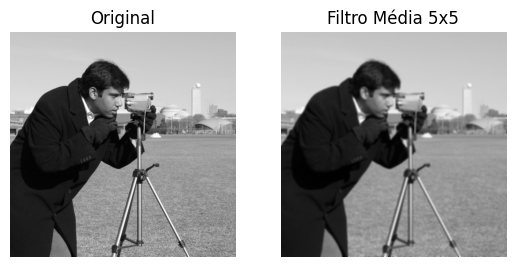

In [5]:
def filtro_media(img, k):
  kernel = np.ones((k, k)) / (k * k)
  return convolucao(img, kernel)

img_filt = filtro_media(img, 5)
implot(img, img_filt, 'Média', '5x5')

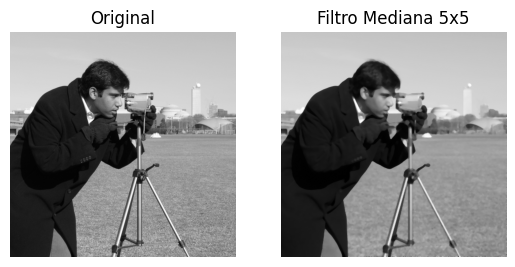

In [6]:
def filtro_mediana(img, k):
  p = k // 2
  img_filt = img.copy()
  for i in range(p, img.shape[0] - p):
    for j in range(p, img.shape[1] - p):
      janela = img[i-p:i+p+1, j-p:j+p+1]
      img_filt[i, j] = np.median(janela)
  return img_filt

img_filt = filtro_mediana(img, 5)
implot(img, img_filt, 'Mediana', '5x5')

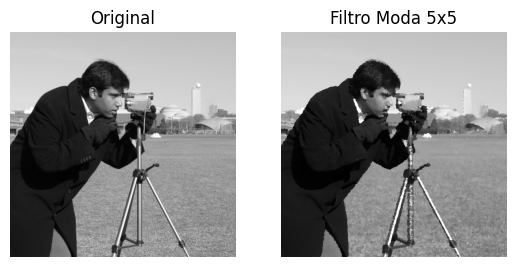

In [7]:
def filtro_moda(img, k):
  p = k // 2
  img_filt = img.copy()
  for i in range(p, img.shape[0] - p):
    for j in range(p, img.shape[1] - p):
      janela = img[i-p:i+p+1, j-p:j+p+1]
      valores, contagem = np.unique(janela, return_counts=True)
      img_filt[i, j] = valores[np.argmax(contagem)]
  return img_filt

img_filt = filtro_moda(img, 5)
implot(img, img_filt, 'Moda', '5x5')

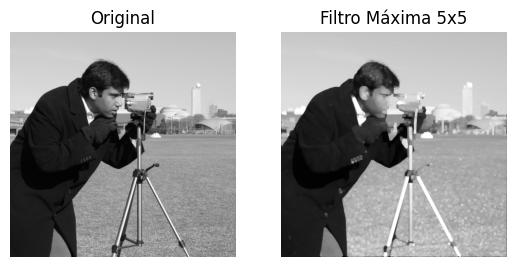

In [8]:
def filtro_maxima(img, k):
  p = k // 2
  img_filt = img.copy()
  for i in range(p, img.shape[0] - p):
    for j in range(p, img.shape[1] - p):
      janela = img[i-p:i+p+1, j-p:j+p+1]
      img_filt[i, j] = np.max(janela)
  return img_filt

img_filt = filtro_maxima(img, 5)
implot(img, img_filt, 'Máxima', '5x5')